In [1]:
import pandas as pd

In [2]:
!pip install pandas mysql-connector-python

In [3]:
!pip install sqlalchemy

In [4]:
import pandas as pd
import numpy as np
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Vishnu@2000",
    database="project"
)
print("Connected Sucessfully")

import sqlalchemy
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password="Vishnu@2000",
    host="localhost",
    database="project"
)

engine = create_engine(url)

from sqlalchemy import text

with engine.connect() as connection:
    result = connection.execute(text("SELECT 1"))
    print("Engine connection successfull!")

import pandas as pd
from sqlalchemy import text

connection = engine.connect() 
# 2. Pull tables into DataFrame
orders_df = pd.read_sql(text("SELECT * FROM orders"), connection)
order_items_df = pd.read_sql(text("SELECT * FROM order_items"), connection)
customer_df = pd.read_sql(text("SELECT * FROM customer"), connection)
print("All three tables!")

# 3. Check data
print(orders_df.head())
print(customer_df.info())

Connected Sucessfully
Engine connection successfull!
All three tables!
   order_id  customer_id  order_status  order_date required_date shipped_date  \
0         1          259             4  01-01-2016    03-01-2016   03-01-2016   
1         2         1212             4  01-01-2016    04-01-2016   03-01-2016   
2         3          523             4  02-01-2016    05-01-2016   03-01-2016   
3         4          175             4  03-01-2016    04-01-2016   05-01-2016   
4         5         1324             4  03-01-2016    06-01-2016   06-01-2016   

   store_id  staff_id  
0         1         2  
1         2         6  
2         2         7  
3         1         3  
4         2         6  
<class 'pandas.DataFrame'>
RangeIndex: 1445 entries, 0 to 1444
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  1445 non-null   int64
 1   first_name   1445 non-null   str  
 2   last_name    1445 non-null   str  
 3 

In [5]:
# Summarize
print(orders_df.describe())
print(customer_df.info())
print(orders_df['order_status'].value_counts())

          order_id  customer_id  order_status     store_id     staff_id
count  1615.000000  1615.000000   1615.000000  1615.000000  1615.000000
mean    808.000000   654.171517      3.778947     1.892260     5.855108
std     466.354658   443.229967      0.693430     0.558395     1.913899
min       1.000000     1.000000      1.000000     1.000000     2.000000
25%     404.500000   237.000000      4.000000     2.000000     6.000000
50%     808.000000   638.000000      4.000000     2.000000     6.000000
75%    1211.500000  1041.500000      4.000000     2.000000     7.000000
max    1615.000000  1445.000000      4.000000     3.000000     9.000000
<class 'pandas.DataFrame'>
RangeIndex: 1445 entries, 0 to 1444
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  1445 non-null   int64
 1   first_name   1445 non-null   str  
 2   last_name    1445 non-null   str  
 3   phone        1445 non-null   str  
 4   email       

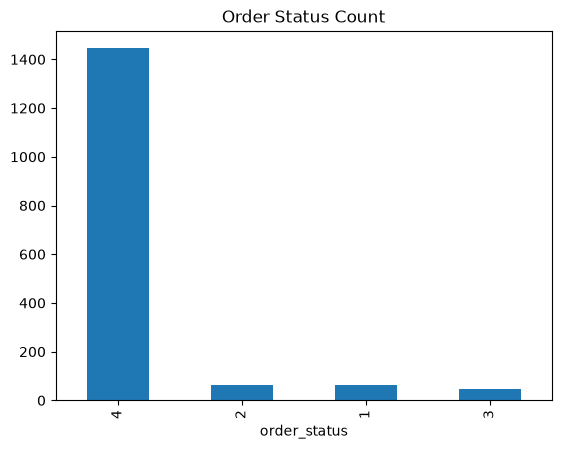

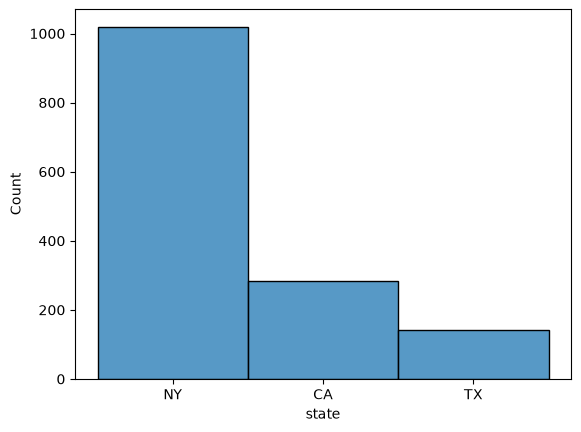

In [6]:
# Charts
import matplotlib.pyplot as plt
import seaborn as sns

orders_df['order_status'].value_counts().plot(kind='bar')
plt.title("Order Status Count")
plt.show()

sns.histplot(customer_df['state'])
plt.show()

In [7]:
# Option 1: Tell pandas days come first (Recommended)
orders_df["order_date"] = pd.to_datetime(orders_df["order_date"], dayfirst=True)

# Option 2: Explicitly state the exact format
orders_df["order_date"] = pd.to_datetime(orders_df["order_date"], format="%d-%m-%Y")

In [9]:
# Calculate Recency
 
latest_date = orders_df ["order_date"].max()
 
recency = orders_df.groupby("customer_id") ["order_date"].max()
 
recency = (latest_date - recency).dt.days
 
print(recency.head())

# Step 3: Calculate Frequency 

frequency = orders_df.groupby("customer_id") ["order_id"].nunique()
 
print(frequency.head())

#Step 4: Calculate Monetary
 
customer_df= orders_df.merge(order_items_df, on="order_id")
 
monetary = customer_df.groupby("customer_id") ["total_price"].sum()
print(type(orders_df))
print(orders_df.head())

customer_id
1     40
2    263
3     68
4    254
5    255
Name: order_date, dtype: int64
customer_id
1    3
2    3
3    3
4    3
5    3
Name: order_id, dtype: int64
<class 'pandas.DataFrame'>
   order_id  customer_id  order_status order_date required_date shipped_date  \
0         1          259             4 2016-01-01    03-01-2016   03-01-2016   
1         2         1212             4 2016-01-01    04-01-2016   03-01-2016   
2         3          523             4 2016-01-02    05-01-2016   03-01-2016   
3         4          175             4 2016-01-03    04-01-2016   05-01-2016   
4         5         1324             4 2016-01-03    06-01-2016   06-01-2016   

   store_id  staff_id  
0         1         2  
1         2         6  
2         2         7  
3         1         3  
4         2         6  


In [ ]:
!pip install pymysql sqlalchemy

In [10]:
#combine recency, frequency, monetary values in to rfm table
import pandas as pd

rfm=pd.concat([recency,frequency,monetary],axis=1)
rfm.columns = ["recency", "frequency","monetary"]
rfm = rfm.reset_index()
print(rfm.head())

   customer_id  recency  frequency  monetary
0            1       40          3  30645.87
1            2      263          3  21653.85
2            3       68          3  26249.81
3            4      254          3  24198.88
4            5      255          3  19442.88


In [11]:
#step 6: segment customer based on total spend

rfm["monetary"] = rfm["monetary"].fillna(0)

rfm["segment"] = pd.cut(
    rfm["monetary"],
    bins=[-float("inf"),20000,30000,float("inf")],
    labels=["Low","Medium","High"]
)
print(rfm.head())

   customer_id  recency  frequency  monetary segment
0            1       40          3  30645.87    High
1            2      263          3  21653.85  Medium
2            3       68          3  26249.81  Medium
3            4      254          3  24198.88  Medium
4            5      255          3  19442.88     Low


In [12]:
#Prepare rfm data for SQL export

rfm["recency"] = rfm["recency"].astype(int)
rfm["monetary"] = rfm["monetary"].round(2)
print(rfm.dtypes)

customer_id       int64
recency           int64
frequency         int64
monetary        float64
segment        category
dtype: object


In [13]:
rfm.to_sql(
    "customer_segments",
    con=engine,
    if_exists="replace",
    index=False
)


print("RFM segmentation exported to SQL successfully!")

RFM segmentation exported to SQL successfully!


In [14]:
print(rfm.isnull().sum())

customer_id    0
recency        0
frequency      0
monetary       0
segment        0
dtype: int64


In [15]:
rfm['Recency'] = rfm['Recency'].fillna(rfm['Recency'].mean())

print(rfm.isnull().sum())

KeyError: 'Recency'